In [12]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
import numpy as np

In [13]:
data_real = pd.read_parquet("/content/final_dataset.parquet")
data_real.head()

,Patient_ID,Sex,Age,BMI,Smoking_Status,ASA,T2DM,HTN,Dl,IHD,...,Pneumonia,Paralytic_ileus,Kidney_failure,Reintervention,Readmission,LOS_days,Survival_days,Recurrence_free_days,Death,Recurrence
0,1,0,84,30.12,1,3,0,1,0,0,...,0,0,0,1,0,27,1322,1322,1,0
1,2,1,85,34.72,0,3,0,1,1,0,...,0,1,0,0,0,11,235,123,1,0
2,3,1,85,28.96,0,2,0,0,0,0,...,0,0,0,0,0,4,2291,2291,0,0
3,4,1,84,28.30,0,3,0,1,1,1,...,0,0,0,0,0,16,1058,1058,0,0
4,5,1,64,38.37,0,2,1,0,1,0,...,0,0,0,1,1,19,2111,1385,0,1


In [14]:
cox_covars = ['Age', 'TNM_stage', 'Node_ratio', 'Adjuvant_CT', 'R_grade', 'Approach', 'Complications']

# Dummy encode and convert to float
data_vif = pd.get_dummies(data_real[cox_covars], drop_first=True).dropna().astype(float)

vif_data = pd.DataFrame()
vif_data["feature"] = data_vif.columns
vif_data["VIF"] = [variance_inflation_factor(data_vif.values, i)
                   for i in range(len(data_vif.columns))]
print(vif_data.sort_values('VIF', ascending=False))

                           feature        VIF
0                              Age  26.154013
5                     TNM_stage_II   9.267274
6                    TNM_stage_III   8.261713
11                   Approach_Open   6.773246
7                     TNM_stage_IV   6.006278
4                      TNM_stage_I   4.855492
10  Approach_Finished Laparoscopic   3.959422
3                    Complications   2.320945
2                      Adjuvant_CT   2.109557
1                       Node_ratio   1.863030
8                       R_grade_R1   1.140295
9                       R_grade_R2   1.023107


VIF for Age turned out high - we replace it with NAT

In [15]:
cox_covars = ['NAT', 'TNM_stage', 'Node_ratio', 'Adjuvant_CT', 'R_grade', 'Approach', 'Complications']

# Dummy encode and convert to float
data_vif = pd.get_dummies(data_real[cox_covars], drop_first=True).dropna().astype(float)

vif_data = pd.DataFrame()
vif_data["feature"] = data_vif.columns
vif_data["VIF"] = [variance_inflation_factor(data_vif.values, i)
                   for i in range(len(data_vif.columns))]
print(vif_data.sort_values('VIF', ascending=False))

                           feature       VIF
11                   Approach_Open  5.958503
6                    TNM_stage_III  5.197275
0                              NAT  5.111292
5                     TNM_stage_II  4.994142
7                     TNM_stage_IV  4.016094
10  Approach_Finished Laparoscopic  3.614373
4                      TNM_stage_I  2.751444
3                    Complications  2.249978
2                      Adjuvant_CT  2.062281
1                       Node_ratio  1.875192
8                       R_grade_R1  1.140635
9                       R_grade_R2  1.031978


## Sensitivity analysis: Age instability and natural cubic splines

Instead of dropping Age for NAT, we test whether Age's numerical instability can be
resolved by (a) ridge regularisation, and (b) a natural cubic spline term, before
concluding that substitution is necessary.

In [16]:
from lifelines import CoxPHFitter
from patsy import dmatrix
import matplotlib.pyplot as plt

duration_col = "Survival_days"
event_col = "Death"

cox_covars_age = ['Age', 'TNM_stage', 'Node_ratio', 'Adjuvant_CT', 'R_grade', 'Approach', 'Complications']

df_cox = data_real[cox_covars_age + [duration_col, event_col]].dropna().copy()
df_cox = pd.get_dummies(df_cox, columns=['TNM_stage', 'R_grade', 'Approach'], drop_first=True)
df_cox = df_cox.astype(float)

### Model 1: Age as a raw linear term, no penalisation
This is expected to be unstable (large SEs / implausible coefficient), motivating
why Age was originally dropped.

In [17]:
cph_age_unpenalised = CoxPHFitter(penalizer=0.0)
cph_age_unpenalised.fit(df_cox, duration_col=duration_col, event_col=event_col)
cph_age_unpenalised.print_summary()

<lifelines.CoxPHFitter: fitted with 333 total observations, 179 right-censored observations>
             duration col = 'Survival_days'
                event col = 'Death'
      baseline estimation = breslow
   number of observations = 333
number of events observed = 154
   partial log-likelihood = -749.46
         time fit was run = 2026-07-09 09:24:48 UTC

---
                                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                       
Age                             0.05      1.05      0.01            0.03            0.07                1.03                1.07
Node_ratio                      1.49      4.43      0.39            0.73            2.25                2.07                9.49
Adjuvant_CT                    -0.32      0.72      0.23           -0.77            0.12                0.46                1.13
Complications                   0.66      1.93      0.18            0.30            1.01                1.35                2.75
TNM_stage_I                    -0.02      0.98      1.04           -2.07            2.02                0.13                7.56
TNM_stage_II                    0.42      1.52      1.02           -1.58            2.43                0.21               11.31
TNM_stage_III                   0.71      2.04      1.02           -1.28            2.71                0.28               15.05
TNM_stage_IV                    2.30     10.02      1.02            0.30            4.30                1.36               73.99
R_grade_R1                     -0.54      0.58      0.35           -1.23            0.14                0.29                1.15
R_grade_R2                      0.31      1.37      1.03           -1.71            2.33                0.18               10.29
Approach_Finished Laparoscopic -0.05      0.95      0.35           -0.74            0.63                0.48                1.88
Approach_Open                   0.13      1.14      0.33           -0.50            0.77                0.60                2.16

                                cmp to     z      p  -log2(p)
covariate                                                    
Age                               0.00  5.35 <0.005     23.44
Node_ratio                        0.00  3.83 <0.005     12.91
Adjuvant_CT                       0.00 -1.43   0.15      2.72
Complications                     0.00  3.62 <0.005     11.75
TNM_stage_I                       0.00 -0.02   0.98      0.03
TNM_stage_II                      0.00  0.41   0.68      0.55
TNM_stage_III                     0.00  0.70   0.48      1.05
TNM_stage_IV                      0.00  2.26   0.02      5.39
R_grade_R1                        0.00 -1.55   0.12      3.05
R_grade_R2                        0.00  0.30   0.76      0.39
Approach_Finished Laparoscopic    0.00 -0.15   0.88      0.19
Approach_Open                     0.00  0.41   0.68      0.55
---
Concordance = 0.79
Partial AIC = 1522.93
log-likelihood ratio test = 169.11 on 12 df
-log2(p) of ll-ratio test = 96.80

### Model 2: Age as a raw linear term, with ridge penalisation (penalizer=0.1)
Same covariate set as the main analysis, but keeping Age instead of substituting NAT.
If ridge alone stabilises Age, this is a cleaner solution than substitution.

In [18]:
cph_age_ridge = CoxPHFitter(penalizer=0.1)
cph_age_ridge.fit(df_cox, duration_col=duration_col, event_col=event_col)
cph_age_ridge.print_summary()

<lifelines.CoxPHFitter: fitted with 333 total observations, 179 right-censored observations>
             duration col = 'Survival_days'
                event col = 'Death'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 333
number of events observed = 154
   partial log-likelihood = -763.87
         time fit was run = 2026-07-09 09:24:57 UTC

---
                                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                       
Age                             0.04      1.04      0.01            0.02            0.05                1.02                1.05
Node_ratio                      1.45      4.25      0.37            0.72            2.17                2.05                8.79
Adjuvant_CT                    -0.28      0.76      0.18           -0.64            0.08                0.53                1.08
Complications                   0.52      1.69      0.16            0.22            0.83                1.24                2.29
TNM_stage_I                    -0.58      0.56      0.27           -1.12           -0.04                0.33                0.96
TNM_stage_II                   -0.26      0.77      0.23           -0.71            0.20                0.49                1.22
TNM_stage_III                  -0.03      0.97      0.23           -0.49            0.43                0.61                1.54
TNM_stage_IV                    1.32      3.74      0.25            0.83            1.81                2.29                6.11
R_grade_R1                     -0.32      0.73      0.31           -0.93            0.30                0.39                1.35
R_grade_R2                      0.21      1.23      0.91           -1.58            2.00                0.21                7.40
Approach_Finished Laparoscopic -0.08      0.92      0.23           -0.53            0.36                0.59                1.43
Approach_Open                   0.11      1.12      0.21           -0.30            0.53                0.74                1.70

                                cmp to     z      p  -log2(p)
covariate                                                    
Age                               0.00  5.29 <0.005     23.00
Node_ratio                        0.00  3.90 <0.005     13.33
Adjuvant_CT                       0.00 -1.52   0.13      2.96
Complications                     0.00  3.34 <0.005     10.23
TNM_stage_I                       0.00 -2.12   0.03      4.89
TNM_stage_II                      0.00 -1.11   0.27      1.91
TNM_stage_III                     0.00 -0.13   0.89      0.16
TNM_stage_IV                      0.00  5.28 <0.005     22.88
R_grade_R1                        0.00 -1.01   0.31      1.69
R_grade_R2                        0.00  0.23   0.82      0.29
Approach_Finished Laparoscopic    0.00 -0.37   0.71      0.49
Approach_Open                     0.00  0.54   0.59      0.77
---
Concordance = 0.79
Partial AIC = 1551.73
log-likelihood ratio test = 140.31 on 12 df
-log2(p) of ll-ratio test = 77.35

### Model 3: Age as a natural cubic spline (df=4), with ridge penalisation
Allows a non-linear Age effect, which may explain why a linear Age term was unstable
(e.g. a threshold/non-linear mortality effect at older ages).

In [19]:
# Build natural cubic spline basis for Age (cr = natural/restricted cubic spline in patsy)
age_spline = dmatrix("cr(Age, df=4) - 1", data=df_cox, return_type="dataframe")
age_spline.columns = [f"Age_spline_{i+1}" for i in range(age_spline.shape[1])]

other_covars = [c for c in df_cox.columns if c not in ['Age', duration_col, event_col]]
df_spline = pd.concat([age_spline, df_cox[other_covars + [duration_col, event_col]]], axis=1)

cph_age_spline = CoxPHFitter(penalizer=0.1)
cph_age_spline.fit(df_spline, duration_col=duration_col, event_col=event_col)
cph_age_spline.print_summary()

<lifelines.CoxPHFitter: fitted with 333 total observations, 179 right-censored observations>
             duration col = 'Survival_days'
                event col = 'Death'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 333
number of events observed = 154
   partial log-likelihood = -758.27
         time fit was run = 2026-07-09 09:25:02 UTC

---
                                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                       
Age_spline_1                    0.66      1.94      1.02           -1.34            2.66                0.26               14.33
Age_spline_2                   -0.53      0.59      0.28           -1.07            0.01                0.34                1.01
Age_spline_3                    0.32      1.38      0.28           -0.23            0.87                0.79                2.38
Age_spline_4                    1.63      5.13      0.49            0.68            2.59                1.97               13.34
Node_ratio                      1.41      4.09      0.37            0.68            2.14                1.97                8.48
Adjuvant_CT                    -0.18      0.83      0.19           -0.55            0.19                0.58                1.21
Complications                   0.50      1.65      0.16            0.19            0.81                1.21                2.24
TNM_stage_I                    -0.55      0.58      0.28           -1.09           -0.01                0.34                0.99
TNM_stage_II                   -0.26      0.77      0.23           -0.72            0.19                0.49                1.21
TNM_stage_III                  -0.05      0.95      0.23           -0.51            0.41                0.60                1.50
TNM_stage_IV                    1.32      3.75      0.25            0.83            1.81                2.29                6.13
R_grade_R1                     -0.31      0.73      0.32           -0.93            0.31                0.40                1.36
R_grade_R2                      0.03      1.03      0.90           -1.74            1.80                0.18                6.02
Approach_Finished Laparoscopic -0.09      0.92      0.23           -0.53            0.36                0.59                1.43
Approach_Open                   0.11      1.12      0.21           -0.30            0.53                0.74                1.70

                                cmp to     z      p  -log2(p)
covariate                                                    
Age_spline_1                      0.00  0.65   0.52      0.95
Age_spline_2                      0.00 -1.92   0.05      4.20
Age_spline_3                      0.00  1.14   0.25      1.98
Age_spline_4                      0.00  3.35 <0.005     10.29
Node_ratio                        0.00  3.78 <0.005     12.65
Adjuvant_CT                       0.00 -0.97   0.33      1.58
Complications                     0.00  3.17 <0.005      9.36
TNM_stage_I                       0.00 -1.98   0.05      4.40
TNM_stage_II                      0.00 -1.13   0.26      1.96
TNM_stage_III                     0.00 -0.22   0.83      0.28
TNM_stage_IV                      0.00  5.27 <0.005     22.82
R_grade_R1                        0.00 -0.98   0.33      1.62
R_grade_R2                        0.00  0.03   0.97      0.04
Approach_Finished Laparoscopic    0.00 -0.39   0.70      0.52
Approach_Open                     0.00  0.54   0.59      0.76
---
Concordance = 0.79
Partial AIC = 1546.54
log-likelihood ratio test = 151.50 on 15 df
-log2(p) of ll-ratio test = 79.44

### Compare model fit: linear Age (ridge) vs spline Age (ridge) vs NAT (ridge)
Use partial log-likelihood / concordance / AIC to compare, not VIF (VIF cannot
adjudicate between constructs, only collinearity within a fixed covariate set).

In [20]:
cox_covars_nat = ['NAT', 'TNM_stage', 'Node_ratio', 'Adjuvant_CT', 'R_grade', 'Approach', 'Complications']
df_nat = data_real[cox_covars_nat + [duration_col, event_col]].dropna().copy()
df_nat = pd.get_dummies(df_nat, columns=['TNM_stage', 'R_grade', 'Approach'], drop_first=True).astype(float)

cph_nat = CoxPHFitter(penalizer=0.1)
cph_nat.fit(df_nat, duration_col=duration_col, event_col=event_col)

comparison = pd.DataFrame({
    "model": ["Age linear (ridge)", "Age spline df=4 (ridge)", "NAT (ridge)"],
    "concordance": [cph_age_ridge.concordance_index_, cph_age_spline.concordance_index_, cph_nat.concordance_index_],
    "log_likelihood": [cph_age_ridge.log_likelihood_, cph_age_spline.log_likelihood_, cph_nat.log_likelihood_],
    "AIC_partial": [cph_age_ridge.AIC_partial_, cph_age_spline.AIC_partial_, cph_nat.AIC_partial_],
})
print(comparison)

                     model  concordance  log_likelihood  AIC_partial
0       Age linear (ridge)     0.788718     -763.866994  1551.733989
1  Age spline df=4 (ridge)     0.792926     -758.272087  1546.544173
2              NAT (ridge)     0.766138     -777.533343  1579.066686


### Visualise the non-linear Age effect (partial hazard)
If Age's effect is markedly
non-linear, that explains the instability of the linear term without requiring
substitution by NAT.

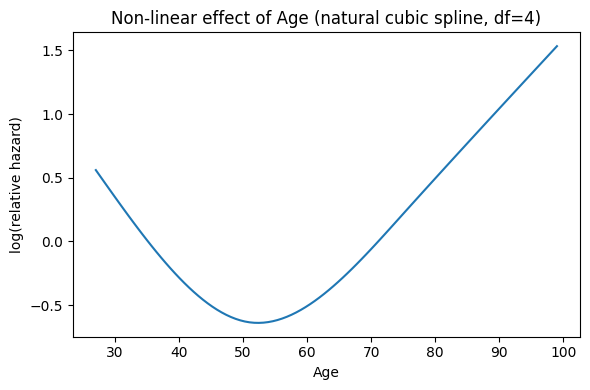

In [21]:
age_range = np.linspace(df_cox['Age'].min(), df_cox['Age'].max(), 100)
age_grid_spline = dmatrix("cr(Age, df=4) - 1", data=pd.DataFrame({"Age": age_range}), return_type="dataframe")
age_grid_spline.columns = age_spline.columns

pred_df = age_grid_spline.copy()
for col in other_covars:
    pred_df[col] = df_spline[col].mean()

partial_hazard = cph_age_spline.predict_partial_hazard(pred_df)

plt.figure(figsize=(6, 4))
plt.plot(age_range, np.log(partial_hazard))
plt.xlabel("Age")
plt.ylabel("log(relative hazard)")
plt.title("Non-linear effect of Age (natural cubic spline, df=4)")
plt.tight_layout()
plt.savefig("age_spline_effect.png", dpi=150)
plt.show()

## VIF for the Age-spline model

Compute VIF for each term in the design matrix that includes Age as a natural cubic
spline (df=4), instead of a single linear Age term. Since the spline basis expands
Age into 4 columns, we report VIF for each spline term individually, as well as a
combined/generalised VIF for the Age block as a whole (since the individual spline
terms are, by construction, correlated with each other and interpreting them one at
a time is not meaningful on its own).

In [22]:
# Reuses age_spline / df_spline / other_covars built in the earlier spline sensitivity analysis cells above.
# If running this section standalone, re-run the cells that build df_cox, age_spline and df_spline first.

vif_input = df_spline.drop(columns=[duration_col, event_col]).astype(float)

vif_spline_data = pd.DataFrame()
vif_spline_data["feature"] = vif_input.columns
vif_spline_data["VIF"] = [variance_inflation_factor(vif_input.values, i)
                           for i in range(len(vif_input.columns))]
print(vif_spline_data.sort_values("VIF", ascending=False))
vif_spline_data.to_csv("vif_output_age_spline.csv", index=False)

                           feature        VIF
2                     Age_spline_3  32.423150
1                     Age_spline_2  22.406525
8                     TNM_stage_II  10.960385
9                    TNM_stage_III   9.439706
10                    TNM_stage_IV   7.288807
7                      TNM_stage_I   7.067721
3                     Age_spline_4   3.441010
13  Approach_Finished Laparoscopic   3.386863
14                   Approach_Open   3.323400
5                      Adjuvant_CT   1.777083
0                     Age_spline_1   1.719312
4                       Node_ratio   1.469227
11                      R_grade_R1   1.104247
6                    Complications   1.086364
12                      R_grade_R2   1.027666


### Generalised VIF (GVIF) for the Age spline block

Because the 4 Age-spline basis columns are jointly one construct, a fairer summary
than 4 separate VIFs is the generalised VIF (GVIF) for the whole block, analogous to
Fox & Monette (1992): fit Age's own spline block against all other covariates as a
multivariate regression, using the determinant-ratio definition of GVIF, then take
GVIF^(1/(2*df)) for a value comparable in scale to a normal VIF.

In [23]:
import numpy as np

def block_gvif(data, block_cols, df_block):
    """Generalised VIF for a block of correlated columns (e.g. spline basis terms),
    following Fox & Monette (1992). Returns GVIF and GVIF^(1/(2*df)).
    """
    corr_all = data.corr()
    other_cols = [c for c in data.columns if c not in block_cols]

    det_all = np.linalg.det(corr_all.values)
    det_block = np.linalg.det(corr_all.loc[block_cols, block_cols].values)
    det_other = np.linalg.det(corr_all.loc[other_cols, other_cols].values)

    gvif = det_block * det_other / det_all
    gvif_scaled = gvif ** (1 / (2 * df_block))
    return gvif, gvif_scaled

age_spline_cols = list(age_spline.columns)
gvif, gvif_scaled = block_gvif(vif_input, age_spline_cols, df_block=len(age_spline_cols))

print(f"Age spline block GVIF: {gvif:.3f}")
print(f"Age spline block GVIF^(1/(2*df)): {gvif_scaled:.3f}  (comparable in scale to sqrt(VIF))")

Age spline block GVIF: 1.396
Age spline block GVIF^(1/(2*df)): 1.043  (comparable in scale to sqrt(VIF))
